# The Causal Effect of Smoking Cessation on Weight Gain: First Version

Michael Duarte Goncalves, Mircea-Adrian Guinea, Tina Sikharulidze

March 2026

## Abstract

We estimate the average causal effect of smoking cessation on body weight change
using data from 1566 cigarette smokers in the National Health and Nutrition
Examination Survey Epidemiologic Follow-up Study (NHEFS). Individuals who quit
smoking between the 1971 baseline and the 1982 follow-up gained more weight than
those who continued. We adjust for nine baseline confounders under exchangeability,
positivity, consistency, and SUTVA. We apply two estimation strategies: inverse
probability weighting with stabilised weights and the parametric g-formula
(standardisation). Both methods yield consistent estimates of approximately 3.4 to
3.5 kg, suggesting that quitting smoking causes a clinically meaningful weight gain
over a decade.

## Introduction

The National Health and Nutrition Examination Survey Data I Epidemiologic Follow-up
Study (NHEFS) is a longitudinal study jointly initiated by the National Center for
Health Statistics and the National Institute on Aging. Participants completed a
baseline visit between 1971 and 1975 and a follow-up visit around 1982. The dataset
we analyse is a subset of 1566 cigarette smokers aged 25 to 74 at baseline who had
complete information on key variables at both visits (Hernan & Robins, 2021, p. 149).

The causal question is: what is the average causal effect of quitting smoking (the
treatment, A) on weight change in kilograms between baseline and follow-up (the
outcome, Y)? A naive comparison of mean weight change between quitters and
non-quitters conflates the treatment effect with confounding from baseline
characteristics that predict both quitting and weight change. We adjust for nine
pre-treatment confounders using inverse probability weighting and the parametric
g-formula following Hernan and Robins (2021, Chapters 12-13).

## Results

We load the NHEFS dataset and select the variables needed for the analysis. The
dataset is already restricted to uncensored individuals with complete data on all
analysis variables.

In [1]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path("data")

TREATMENT = "qsmk"
OUTCOME = "wt82_71"
CONFOUNDERS = [
    "sex", "age", "race", "education",
    "smokeintensity", "smokeyrs",
    "active", "exercise", "wt71",
]
CONTINUOUS_COVARIATES = ["age", "wt71", "smokeintensity", "smokeyrs"]
CATEGORICAL_COVARIATES = ["education", "exercise", "active"]

nhefs = pd.read_csv(DATA_DIR / "nhefs_complete.csv")
print(f"Dataset: {nhefs.shape[0]} individuals, {nhefs.shape[1]} variables")

Dataset: 1566 individuals, 67 variables


We verify there are no missing values in the analysis columns.

In [2]:
analysis_cols = [TREATMENT, OUTCOME] + CONFOUNDERS
missing = nhefs[analysis_cols].isnull().sum()
print(missing[missing > 0] if missing.any() else "No missing values")

No missing values


We reproduce the descriptive statistics from Table 12.1 of Hernan and Robins (2021,
p. 149) to examine baseline differences between quitters and non-quitters.

In [3]:
nhefs["education_univ"] = (nhefs["education"] >= 4).astype(int)
nhefs["little_exercise"] = (nhefs["exercise"] == 2).astype(int)
nhefs["inactive_life"] = (nhefs["active"] == 2).astype(int)

table_vars = {
    "Age, years": ("age", False),
    "Men, %": ("sex", True),
    "White, %": ("race", True),
    "University, %": ("education_univ", True),
    "Weight, kg": ("wt71", False),
    "Cigarettes/day": ("smokeintensity", False),
    "Years smoking": ("smokeyrs", False),
    "Little exercise, %": ("little_exercise", True),
    "Inactive life, %": ("inactive_life", True),
}

rows = []
for label, (var, is_pct) in table_vars.items():
    vals = []
    for a in [1, 0]:
        subset = nhefs.loc[nhefs[TREATMENT] == a, var]
        if is_pct:
            if var in ("sex", "race"):
                vals.append(round((1 - subset.mean()) * 100, 1))
            else:
                vals.append(round(subset.mean() * 100, 1))
        else:
            vals.append(round(subset.mean(), 1))
    rows.append([label] + vals)

table121 = pd.DataFrame(rows, columns=["Characteristic", "A=1", "A=0"])
table121 = table121.set_index("Characteristic")
table121

,A=1,A=0
Characteristic,,
"Age, years",46.2,42.8
"Men, %",54.6,46.6
"White, %",91.1,85.4
"University, %",22.6,17.8
"Weight, kg",72.4,70.3
Cigarettes/day,18.6,21.2
Years smoking,26.0,24.1
"Little exercise, %",40.7,37.9
"Inactive life, %",11.2,8.9


Quitters were older, heavier, and smoked fewer cigarettes per day compared with
non-quitters, confirming the patterns reported by Hernan and Robins. These
imbalances motivate the need for confounding adjustment.

We now plot the distribution of weight change by treatment group to see the
unadjusted difference.

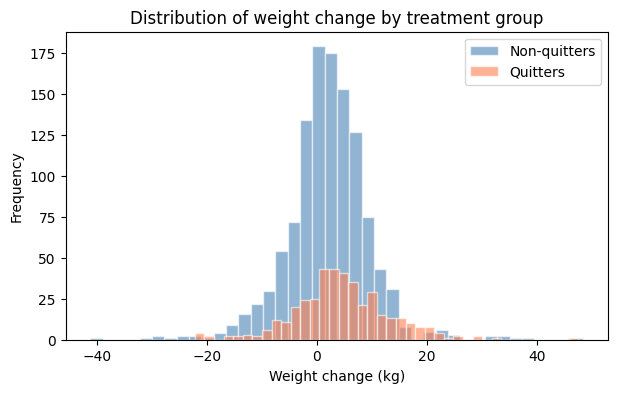

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
for a, label, color in [(0, "Non-quitters", "steelblue"),
                         (1, "Quitters", "coral")]:
    subset = nhefs.loc[nhefs[TREATMENT] == a, OUTCOME]
    ax.hist(subset, bins=40, alpha=0.6, label=label, color=color,
            edgecolor="white")
ax.set_xlabel("Weight change (kg)")
ax.set_ylabel("Frequency")
ax.set_title("Distribution of weight change by treatment group")
ax.legend()
plt.show()

We compute the naive (unadjusted) difference in mean weight change between quitters
and non-quitters. This estimate is confounded by baseline differences between groups.

In [5]:
naive_ate = (nhefs.loc[nhefs[TREATMENT] == 1, OUTCOME].mean()
            - nhefs.loc[nhefs[TREATMENT] == 0, OUTCOME].mean())
print(f"Naive ATE: {naive_ate:.2f} kg")

Naive ATE: 2.54 kg


### Causal DAG

We draw the assumed causal structure. The nine confounders L cause both treatment
A (smoking cessation) and outcome Y (weight change). Under conditional
exchangeability given L, adjusting for these confounders blocks all backdoor paths
(Hernan & Robins, 2021, Chapters 6-7).

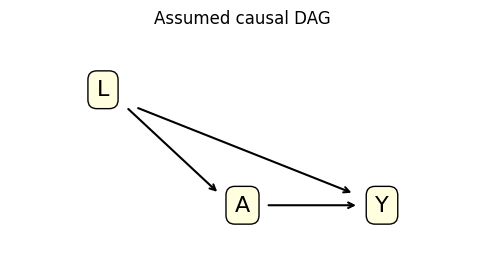

In [6]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.set_xlim(0, 10)
ax.set_ylim(0, 4)
ax.axis("off")

nodes = {"L": (2, 3), "A": (5, 1), "Y": (8, 1)}
for name, (x, y) in nodes.items():
    ax.annotate(name, (x, y), fontsize=16, ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.4", fc="lightyellow",
                          ec="black"))

ax.annotate("", xy=(4.5, 1.2), xytext=(2.5, 2.7),
            arrowprops=dict(arrowstyle="->", lw=1.5))
ax.annotate("", xy=(7.4, 1.2), xytext=(2.7, 2.7),
            arrowprops=dict(arrowstyle="->", lw=1.5))
ax.annotate("", xy=(7.5, 1), xytext=(5.5, 1),
            arrowprops=dict(arrowstyle="->", lw=1.5))

ax.set_title("Assumed causal DAG")
plt.show()

The DAG encodes three sets of edges. First, L causes A: baseline characteristics
such as age, sex, smoking intensity, and weight influence whether a person quits
smoking. Second, L causes Y: the same characteristics affect weight change
independently of quitting. Third, A causes Y: smoking cessation itself alters
metabolism and appetite, leading to weight gain. There is no edge from A to L
because L is measured at baseline before the treatment decision.

The only backdoor path from A to Y is A <- L -> Y. Conditioning on L blocks
this path because L is a non-collider on it. No variable on this path is a
collider, so conditioning on L does not open any spurious association
(Hernan & Robins, 2021, pp. 69-78).

### Identification assumptions

We state the four identification assumptions required to give the adjusted
association a causal interpretation.

Exchangeability (no unmeasured confounding) requires that, conditional on the nine
measured confounders L, the potential outcomes are independent of treatment
assignment (Hernan & Robins, 2021, pp. 27-30).

Positivity requires that, for every stratum of confounders with nonzero probability,
both treatment levels are observed (Hernan & Robins, 2021, pp. 30-31).

Consistency states that the observed outcome for an individual who received treatment
level a equals their potential outcome under that treatment (Hernan & Robins, 2021,
pp. 31-35).

SUTVA requires that the potential outcome for individual i depends only on their own
treatment assignment, not on others' treatment. In the NHEFS context, this is
plausible because smoking cessation is largely an individual decision and the survey
sampled participants from across the United States (Hernan & Robins, 2021, pp. 3-4).

### Propensity score estimation

We fit a logistic regression of treatment on the nine confounders with quadratic
terms for continuous covariates, and check overlap between treatment groups
(Hernan & Robins, 2021, p. 151).

In [7]:
propensity_terms = []
for var in CONFOUNDERS:
    if var in CATEGORICAL_COVARIATES:
        propensity_terms.append(f"C({var})")
    else:
        propensity_terms.append(var)
    if var in CONTINUOUS_COVARIATES:
        propensity_terms.append(f"I({var}**2)")

propensity_formula = f"{TREATMENT} ~ " + " + ".join(propensity_terms)

ps_model = smf.logit(propensity_formula, data=nhefs).fit(disp=0)
nhefs["ps"] = ps_model.predict()

print(f"Propensity score range: ({nhefs['ps'].min():.4f}, "
      f"{nhefs['ps'].max():.4f})")

Propensity score range: (0.0510, 0.7769)


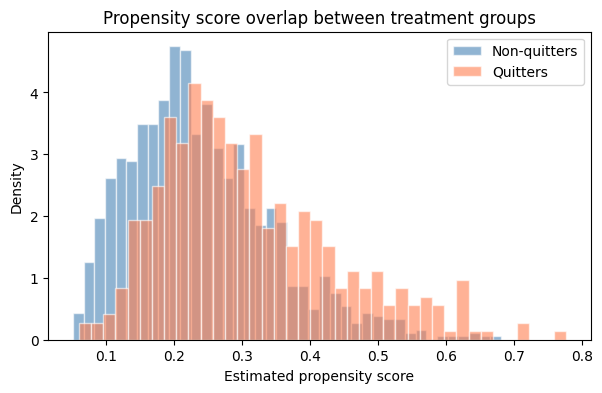

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
for a, label, color in [(0, "Non-quitters", "steelblue"),
                         (1, "Quitters", "coral")]:
    subset = nhefs.loc[nhefs[TREATMENT] == a, "ps"]
    ax.hist(subset, bins=40, alpha=0.6, label=label, color=color,
            edgecolor="white", density=True)
ax.set_xlabel("Estimated propensity score")
ax.set_ylabel("Density")
ax.set_title("Propensity score overlap between treatment groups")
ax.legend()
plt.show()

The propensity score distributions overlap adequately between the two groups,
suggesting that positivity is approximately satisfied.

### IP weighting

We start with inverse probability (IP) weighting. Instead of modelling the outcome,
we model the probability of receiving treatment (the propensity score) and reweight
observations so that treatment becomes independent of confounders. This mimics a
randomised experiment: we undo selection bias by giving more weight to individuals
who were unlikely to receive their actual treatment (Hernan & Robins, 2021, p. 151).

We use stabilised weights SW = f(A) / f(A|L), which have mean 1 and are less
variable than nonstabilised weights (Hernan & Robins, 2021, p. 153).

In [9]:
p_treated = nhefs[TREATMENT].mean()

nhefs["sw"] = np.where(
    nhefs[TREATMENT] == 1,
    p_treated / nhefs["ps"],
    (1 - p_treated) / (1 - nhefs["ps"]),
)

print(f"Stabilised weights -- mean: {nhefs['sw'].mean():.2f}, "
      f"min: {nhefs['sw'].min():.2f}, max: {nhefs['sw'].max():.2f}")

Stabilised weights -- mean: 1.00, min: 0.33, max: 4.30


We fit the marginal structural model $E[Y(a)] = \beta_0 + \beta_1 \times a$ using weighted
least squares with the stabilised weights. The coefficient $\beta_1$ estimates the
average causal effect. We use the robust variance estimator
(Hernan & Robins, 2021, p. 152).

In [10]:
msm = smf.wls(
    f"{OUTCOME} ~ {TREATMENT}", data=nhefs, weights=nhefs["sw"],
).fit(cov_type="HC1")

ate_ipw = msm.params[TREATMENT]
ci_ipw = msm.conf_int().loc[TREATMENT].values

print(f"IP weighting ATE: {ate_ipw:.1f} kg")
print(f"95% CI: ({ci_ipw[0]:.1f}, {ci_ipw[1]:.1f})")

IP weighting ATE: 3.4 kg
95% CI: (2.4, 4.5)


We verify that IP weighting reduced the covariate imbalance by comparing weighted
and unweighted standardised mean differences in a love plot.

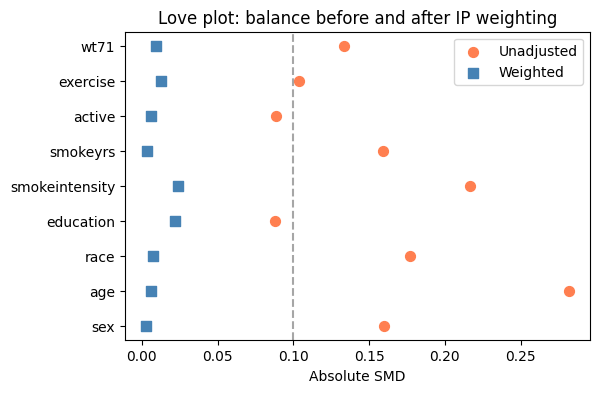

In [11]:
treated = nhefs[nhefs[TREATMENT] == 1]
control = nhefs[nhefs[TREATMENT] == 0]

smd_balance = []
for var in CONFOUNDERS:
    d_raw = treated[var].mean() - control[var].mean()
    s = np.sqrt((treated[var].var() + control[var].var()) / 2)
    smd_raw = d_raw / s if s > 0 else 0

    wt_mean_1 = np.average(treated[var], weights=treated["sw"])
    wt_mean_0 = np.average(control[var], weights=control["sw"])
    smd_wtd = (wt_mean_1 - wt_mean_0) / s if s > 0 else 0

    smd_balance.append({
        "Variable": var,
        "Unadjusted": abs(smd_raw),
        "Weighted": abs(smd_wtd),
    })

smd_bal_df = pd.DataFrame(smd_balance)

fig, ax = plt.subplots(figsize=(6, 4))
y_pos = np.arange(len(smd_bal_df))
ax.scatter(smd_bal_df["Unadjusted"], y_pos, marker="o",
           label="Unadjusted", color="coral", s=50)
ax.scatter(smd_bal_df["Weighted"], y_pos, marker="s",
           label="Weighted", color="steelblue", s=50)
ax.set_yticks(y_pos)
ax.set_yticklabels(smd_bal_df["Variable"])
ax.axvline(0.1, color="grey", linestyle="--", alpha=0.7)
ax.set_xlabel("Absolute SMD")
ax.set_title("Love plot: balance before and after IP weighting")
ax.legend()
plt.show()

### Parametric g-formula (standardisation)

IP weighting models the treatment side; the g-formula takes the opposite approach
and models the outcome directly. We fit a regression of weight change on treatment
and confounders, then predict each person's outcome under "everyone quits" and
"nobody quits." The difference in means is the ATE (Hernan & Robins, 2021,
pp. 163-164).

We use both methods because they rely on different assumptions. If the propensity
score model is wrong but the outcome model is right, the g-formula is still
consistent, and vice versa. Getting similar numbers from both gives us more
confidence in the result.

The outcome model follows Program 13.3 (Hernan & Robins, 2021, p. 165): all nine
confounders, quadratic terms for continuous covariates, and a product term between
treatment and smoking intensity.

In [12]:
outcome_terms = [TREATMENT]
for var in CONFOUNDERS:
    if var in CATEGORICAL_COVARIATES:
        outcome_terms.append(f"C({var})")
    else:
        outcome_terms.append(var)
    if var in CONTINUOUS_COVARIATES:
        outcome_terms.append(f"I({var}**2)")
outcome_terms.append(f"{TREATMENT}:smokeintensity")

outcome_formula = f"{OUTCOME} ~ " + " + ".join(outcome_terms)
outcome_mod = smf.ols(outcome_formula, data=nhefs).fit()

We compute the standardised predictions under A = 1 (everyone quits) and A = 0
(nobody quits), and use the bootstrap for confidence intervals following Technical
Point 13.1 (Hernan & Robins, 2021, p. 166).

In [13]:
nhefs_a1 = nhefs.assign(**{TREATMENT: 1})
nhefs_a0 = nhefs.assign(**{TREATMENT: 0})

y_hat_1 = outcome_mod.predict(nhefs_a1)
y_hat_0 = outcome_mod.predict(nhefs_a0)

ate_gformula = y_hat_1.mean() - y_hat_0.mean()

rng = np.random.default_rng(seed=42)
n_boot = 500
n = len(nhefs)
boot_ates = np.empty(n_boot)

for b in range(n_boot):
    idx = rng.choice(n, size=n, replace=True)
    boot_df = nhefs.iloc[idx].reset_index(drop=True)
    mod = smf.ols(outcome_formula, data=boot_df).fit()
    boot_a1 = boot_df.assign(**{TREATMENT: 1})
    boot_a0 = boot_df.assign(**{TREATMENT: 0})
    boot_ates[b] = mod.predict(boot_a1).mean() - mod.predict(boot_a0).mean()

ci_gf_low = np.percentile(boot_ates, 2.5)
ci_gf_high = np.percentile(boot_ates, 97.5)

print(f"G-formula ATE: {ate_gformula:.1f} kg")
print(f"95% bootstrap CI: ({ci_gf_low:.1f}, {ci_gf_high:.1f})")

G-formula ATE: 3.5 kg
95% bootstrap CI: (2.6, 4.5)


### Summary of estimates

In [14]:
methods = [
    ("Naive (unadjusted)", naive_ate, None, None),
    ("IPW (stabilised)", ate_ipw, ci_ipw[0], ci_ipw[1]),
    ("G-formula", ate_gformula, ci_gf_low, ci_gf_high),
]

rows = []
for name, ate, lo, hi in methods:
    ci_str = f"({lo:.1f}, {hi:.1f})" if lo is not None else "--"
    bias = round(naive_ate - ate, 1) if name != "Naive (unadjusted)" else "--"
    rows.append({
        "Method": name,
        "ATE (kg)": round(ate, 1),
        "95% CI": ci_str,
        "Bias removed (kg)": bias,
    })

final = pd.DataFrame(rows).set_index("Method")
final

,ATE (kg),95% CI,Bias removed (kg)
Method,,,
Naive (unadjusted),2.5,--,--
IPW (stabilised),3.4,"(2.4, 4.5)",-0.9
G-formula,3.5,"(2.6, 4.5)",-1.0


Both adjusted estimators yield ATE estimates around 3.4 to 3.5 kg, consistent with
Hernan and Robins (2021, pp. 152, 165). IP weighting models the treatment side and
the g-formula models the outcome side. They could each fail if their particular model
is wrong, but they agree closely here. That agreement is the best evidence we have
that the result is real rather than an artefact of any single modelling choice.

## Discussion

We estimated the average causal effect of smoking cessation on weight change using
two methods applied to NHEFS data from 1566 cigarette smokers. Both IP weighting
and the parametric g-formula produce estimates around 3.4 to 3.5 kg with overlapping
confidence intervals, consistent with Hernan and Robins (2021, Chapters 12-13).

Why use both methods? Because each can fail differently. IP weighting needs the
propensity score model to be right; the g-formula needs the outcome model to be
right. The fact that they agree tells us the result is not driven by one particular
modelling choice.

Several limitations apply. First, we assume conditional exchangeability given nine
measured confounders. Unmeasured confounders like motivation to change health
behaviours or dietary changes could bias the results. Second, we restricted the
analysis to the 1566 individuals with observed outcomes. If treatment affects the
probability of being censored, this introduces selection bias (Hernan & Robins,
2021, pp. 158-159). Third, both strategies rely on correct model specification.

Future work could incorporate doubly robust estimation for insurance against
misspecification of a single model, censoring weights to address potential selection
bias from loss to follow-up, and flexible machine learning methods like double
machine learning to relax functional form assumptions.